# L1 Benchmark Analysis

**Focus: Network bottlenecks & algorithm comparison**

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Load Data

In [ ]:
# Configure which file to analyze
DATA_FILE = 'output/playwright-myers-baseline.json'

def load_algo_metrics(filepath):
    """Extract per-algorithm+mode timing metrics"""
    with open(filepath) as f:
        results = json.load(f)
    
    rows = []
    for r in results:
        if not r.get('success'): continue
        test = r['id']
        for link in r['analysis'].get('linkMetrics', []):
            if 'diff' not in link or 'metrics' not in link['diff']: continue
            for m in link['diff']['metrics']:
                if 'error' in m: continue
                
                algo = m.get('algorithm', 'unknown')
                mode = m.get('mode', 'unknown')  # Now explicitly logged
                
                timings = m.get('timings', {})
                parseMs = timings.get('parseMs', 0)
                
                # Get the appropriate compare time based on mode
                if mode == 'diff':
                    compareMs = timings.get('diffMs', 0)
                else:
                    compareMs = timings.get('similarityMs', 0)
                
                sizeBytes = m.get('sizeBytes', 0)
                
                rows.append({
                    'test': test,
                    'url': link['url'],
                    'algo': algo,
                    'mode': mode,
                    'parseMs': parseMs,
                    'compareMs': compareMs,
                    'similarity': m.get('similarity', 0),
                    'label': m.get('label', 'unknown'),
                    'sizeBytes': sizeBytes
                })
    return pd.DataFrame(rows)

def load_network_metrics(filepath):
    """Extract network-level timing (algorithm-agnostic)"""
    with open(filepath) as f:
        results = json.load(f)
    
    rows = []
    for r in results:
        if not r.get('success'): continue
        test = r['id']
        for link in r['analysis'].get('linkMetrics', []):
            if 'diff' not in link or 'timings' not in link['diff']: continue
            t = link['diff']['timings']
            rows.append({
                'test': test,
                'url': link['url'],
                'liveMs': t.get('liveFetchMs', 0),
                'snapMs': t.get('snapshotDownloadMs', 0),
                'algoMs': t.get('diffMs', 0),
                'totalMs': t.get('totalMs', 0)
            })
    return pd.DataFrame(rows)

# Load data
if not Path(DATA_FILE).exists():
    raise FileNotFoundError(f'No benchmark results found at {DATA_FILE}!\n'
                          f'Run: npm run benchmark:playwright')

algo_df = load_algo_metrics(DATA_FILE)
net_df = load_network_metrics(DATA_FILE)

algos = algo_df['algo'].unique()
modes = algo_df['mode'].unique()

print(f"Data file: {Path(DATA_FILE).name}")
print(f"Loaded {len(net_df)} links, {len(algo_df)} algorithm+mode runs")
print(f"Algorithms: {', '.join(algos)}")
print(f"Modes: {', '.join(modes)}")

Data file: playwright-myers-baseline.json
Loaded 63 links, 228 algorithm+mode runs
Algorithms: myers-word, myers-block
Modes: similarity, diff


In [ ]:
algo_df.head()

,test,url,algo,mode,parseMs,compareMs,similarity,label,sizeBytes
0,wikipedia-main,https://en.wikipedia.org/wiki/Wikipedia,myers-word,similarity,485.1,1.0,0.998987,unchanged,0
1,wikipedia-main,https://en.wikipedia.org/wiki/Wikipedia,myers-block,similarity,377.4,0.3,0.973373,minor,0
2,wikipedia-main,https://en.wikipedia.org/wiki/Wikipedia,myers-word,diff,365.1,3.0,0.998987,unchanged,266545
3,wikipedia-main,https://en.wikipedia.org/wiki/Wikipedia,myers-block,diff,684.5,1.9,0.973373,minor,209450
4,wikipedia-main,https://en.wikipedia.org/wiki/Free_content,myers-word,similarity,60.0,0.2,0.999800,unchanged,0


Time Breakdown by Configuration

Per-configuration analysis showing how network (constant) and compute (variable) times contribute to total time.
Configurations vary by algorithm (myers-word vs myers-block) and mode (similarity vs diff).

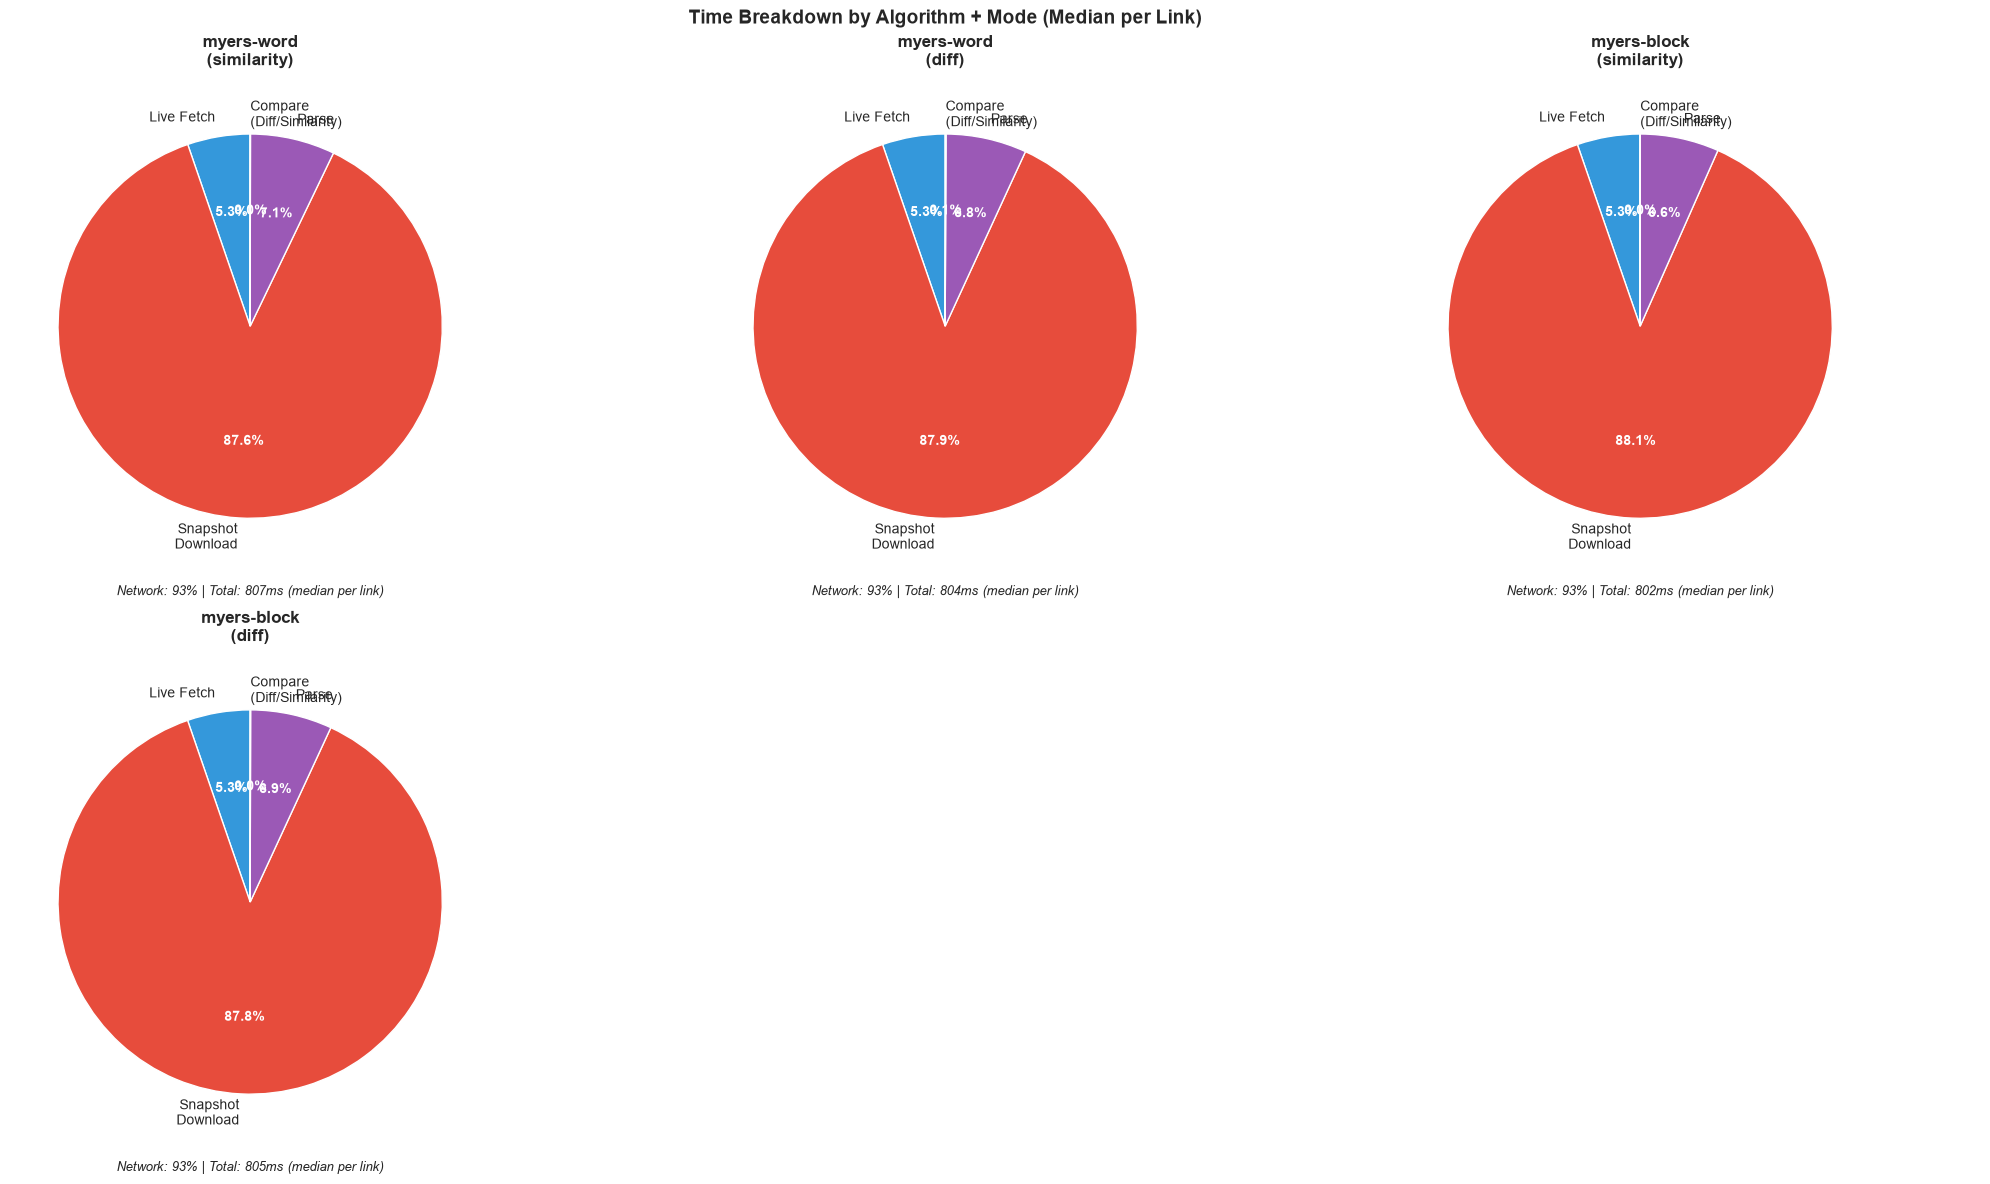

=== TIME BREAKDOWN BY CONFIGURATION (MEDIAN PER LINK) ===
Network (constant across configs): 749.3ms
  - Live fetch:     42.5ms
  - Snapshot:       706.8ms

myers-word (similarity):
  Parse:      57.4ms
  Compare:     0.2ms
  Compute:    57.6ms (  7.1%)
  Total:     806.9ms

myers-word (diff):
  Parse:      54.6ms
  Compare:     0.6ms
  Compute:    55.2ms (  6.9%)
  Total:     804.5ms

myers-block (similarity):
  Parse:      53.1ms
  Compare:     0.1ms
  Compute:    53.2ms (  6.6%)
  Total:     802.5ms

myers-block (diff):
  Parse:      55.2ms
  Compare:     0.3ms
  Compute:    55.5ms (  6.9%)
  Total:     804.8ms



In [ ]:
# Calculate overall network times (constant across all configs)
live_median = net_df['liveMs'].median()
snap_median = net_df['snapMs'].median()

# Calculate per-config compute times
configs = []
for algo in algos:
    for mode in modes:
        a = algo_df[(algo_df['algo'] == algo) & (algo_df['mode'] == mode)]
        if len(a) == 0: continue
        
        parse_median = a['parseMs'].median()
        compare_median = a['compareMs'].median()
        
        total = live_median + snap_median + parse_median + compare_median
        
        configs.append({
            'label': f'{algo}\n({mode})',
            'algo': algo,
            'mode': mode,
            'live': live_median,
            'snap': snap_median,
            'parse': parse_median,
            'compare': compare_median,
            'total': total
        })

# Create pie charts
n_configs = len(configs)
cols = min(3, n_configs)
rows = (n_configs + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(7*cols, 6*rows))
if n_configs == 1:
    axes = [axes]
else:
    axes = axes.flatten() if n_configs > 1 else [axes]

colors = ['#3498db', '#e74c3c', '#9b59b6', '#2ecc71']
labels = ['Live Fetch', 'Snapshot\nDownload', 'Parse', 'Compare\n(Diff/Similarity)']

for idx, config in enumerate(configs):
    ax = axes[idx]
    
    sizes = [config['live'], config['snap'], config['parse'], config['compare']]
    
    wedges, texts, autotexts = ax.pie(sizes, labels=labels, colors=colors,
                                       autopct='%1.1f%%', startangle=90, 
                                       textprops={'fontsize': 10})
    for a in autotexts:
        a.set_color('white')
        a.set_fontweight('bold')
    
    ax.set_title(config['label'], fontsize=12, fontweight='bold', pad=15)
    
    # Add timing details below chart
    network_pct = (config['live'] + config['snap']) / config['total'] * 100
    ax.text(0, -1.4, f"Network: {network_pct:.0f}% | Total: {config['total']:.0f}ms (median per link)",
           ha='center', fontsize=9, style='italic')

# Hide extra subplots
for idx in range(n_configs, len(axes)):
    axes[idx].axis('off')

plt.suptitle('Time Breakdown by Algorithm + Mode (Median per Link)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# Summary stats
print('=== TIME BREAKDOWN BY CONFIGURATION (MEDIAN PER LINK) ===')
print(f'Network (constant across configs): {live_median + snap_median:.1f}ms')
print(f'  - Live fetch:     {live_median:.1f}ms')
print(f'  - Snapshot:       {snap_median:.1f}ms\n')

for config in configs:
    compute = config['parse'] + config['compare']
    total = config['total']
    
    print(f"{config['algo']} ({config['mode']}):")
    print(f"  Parse:    {config['parse']:6.1f}ms")
    print(f"  Compare:  {config['compare']:6.1f}ms")
    print(f"  Compute:  {compute:6.1f}ms ({compute/total*100:5.1f}%)")
    print(f"  Total:    {total:6.1f}ms\n")

## 4. Algorithm Performance Comparison

Comparing parse and comparison times across algorithms and modes (median per link).

=== ALGORITHM PERFORMANCE (MEDIAN PER LINK) ===

myers-word (similarity): 57 links
  Parse:     57.4ms median
  Compare:    0.2ms median

myers-word (diff): 57 links
  Parse:     54.6ms median
  Compare:    0.6ms median
  Size:      26.8 KB median

myers-block (similarity): 57 links
  Parse:     53.1ms median
  Compare:    0.1ms median

myers-block (diff): 57 links
  Parse:     55.2ms median
  Compare:    0.3ms median
  Size:      21.2 KB median


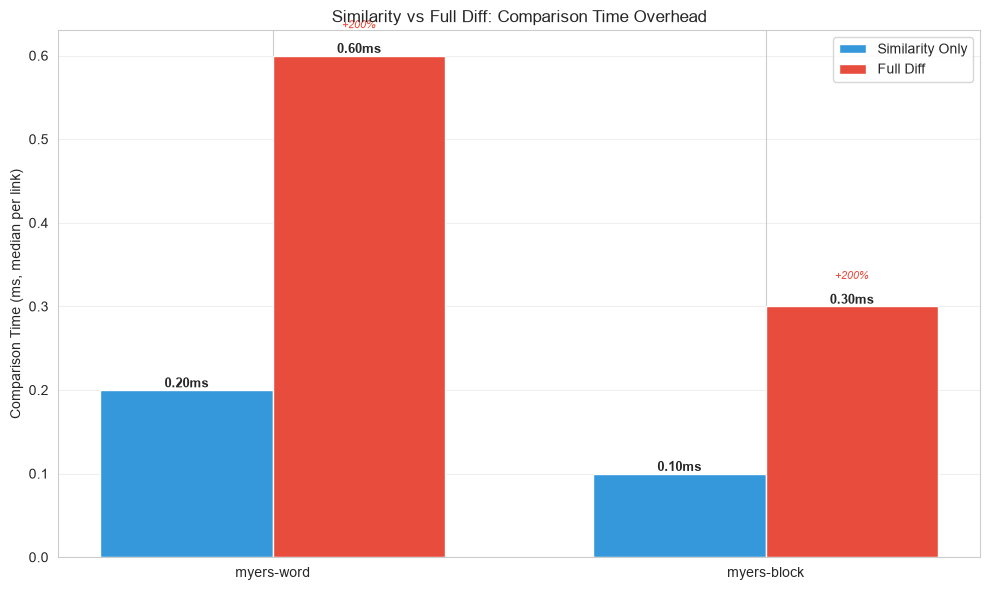

In [ ]:
print(f'=== ALGORITHM PERFORMANCE (MEDIAN PER LINK) ===')
for algo in algos:
    for mode in modes:
        a = algo_df[(algo_df['algo'] == algo) & (algo_df['mode'] == mode)]
        if len(a) == 0: continue
        
        print(f"\n{algo} ({mode}): {len(a)} links")
        print(f"  Parse:   {a['parseMs'].median():6.1f}ms median")
        print(f"  Compare: {a['compareMs'].median():6.1f}ms median")
        if mode == 'diff':
            print(f"  Size:    {a['sizeBytes'].median()/1024:6.1f} KB median")

# Visual: Compare calculation time (diff vs similarity) for each algorithm
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(algos))
w = 0.35

sim_times = []
diff_times = []
for a in algos:
    sim_data = algo_df[(algo_df['algo']==a) & (algo_df['mode']=='similarity')]
    diff_data = algo_df[(algo_df['algo']==a) & (algo_df['mode']=='diff')]
    
    sim_times.append(sim_data['compareMs'].median() if len(sim_data) > 0 else 0)
    diff_times.append(diff_data['compareMs'].median() if len(diff_data) > 0 else 0)

bars1 = ax.bar(x - w/2, sim_times, w, label='Similarity Only', color='#3498db')
bars2 = ax.bar(x + w/2, diff_times, w, label='Full Diff', color='#e74c3c')

# Add value labels
for i, (s, d) in enumerate(zip(sim_times, diff_times)):
    if s > 0:
        ax.text(i - w/2, s, f'{s:.2f}ms', ha='center', va='bottom', fontweight='bold', fontsize=9)
    if d > 0:
        ax.text(i + w/2, d, f'{d:.2f}ms', ha='center', va='bottom', fontweight='bold', fontsize=9)
        # Show overhead percentage
        if s > 0:
            overhead_pct = ((d - s) / s) * 100
            ax.text(i + w/2, d + max(diff_times)*0.05, f'+{overhead_pct:.0f}%', 
                   ha='center', va='bottom', fontsize=8, color='#e74c3c', style='italic')

ax.set_ylabel('Comparison Time (ms, median per link)')
ax.set_title('Similarity vs Full Diff: Comparison Time Overhead')
ax.set_xticks(x)
ax.set_xticklabels(algos)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Comparison Time Distributions

Distribution of comparison times showing median vs mean and highlighting outliers.
Note: Top 1% outliers are filtered from visualization but reported in statistics.

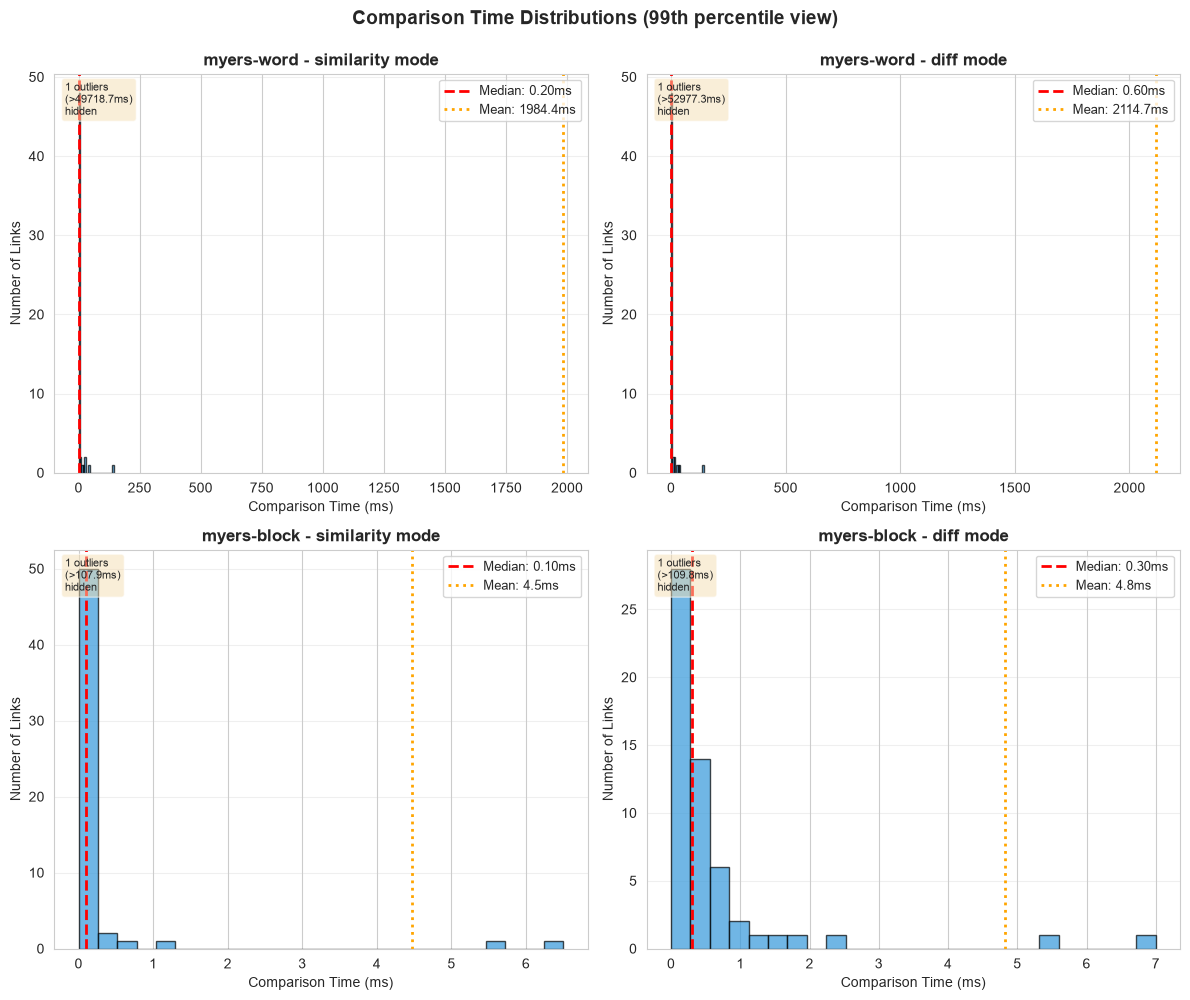


=== COMPARISON TIME STATISTICS (PER LINK) ===
myers-word (similarity):
  Median: 0.20ms | 75th: 0.5ms | 95th: 29.3ms | Max: 112814.5ms
myers-word (diff):
  Median: 0.60ms | 75th: 2.1ms | 95th: 33.8ms | Max: 120221.4ms
myers-block (similarity):
  Median: 0.10ms | 75th: 0.2ms | 95th: 2.0ms | Max: 236.9ms
myers-block (diff):
  Median: 0.30ms | 75th: 0.6ms | 95th: 3.1ms | Max: 240.7ms


In [ ]:
# Distribution of comparison times per algorithm+mode
configs = [(algo, mode) for algo in algos for mode in modes]
n_configs = len(configs)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (algo, mode) in enumerate(configs):
    if idx >= 4:  # Only 4 slots in 2x2
        break
        
    data = algo_df[(algo_df['algo'] == algo) & (algo_df['mode'] == mode)]
    
    if len(data) == 0:
        axes[idx].text(0.5, 0.5, 'No data', ha='center', va='center')
        axes[idx].set_title(f'{algo} ({mode})')
        continue
    
    median_val = data['compareMs'].median()
    mean_val = data['compareMs'].mean()
    
    # Remove extreme outliers for better visualization (keep 99th percentile)
    q99 = data['compareMs'].quantile(0.99)
    filtered_data = data[data['compareMs'] <= q99]['compareMs']
    
    # Vertical histogram (bins on bottom)
    axes[idx].hist(filtered_data, bins=25, color='#3498db', alpha=0.7, edgecolor='black')
    
    axes[idx].axvline(median_val, color='red', linestyle='--', linewidth=2,
                     label=f'Median: {median_val:.2f}ms')
    axes[idx].axvline(mean_val, color='orange', linestyle=':', linewidth=2,
                     label=f'Mean: {mean_val:.1f}ms')
    
    axes[idx].set_xlabel('Comparison Time (ms)')
    axes[idx].set_ylabel('Number of Links')
    axes[idx].set_title(f'{algo} - {mode} mode', fontweight='bold', fontsize=12)
    axes[idx].legend(fontsize=9, loc='upper right')
    axes[idx].grid(axis='y', alpha=0.3)
    
    # Add text annotation for outliers if any were filtered
    n_outliers = len(data) - len(filtered_data)
    if n_outliers > 0:
        axes[idx].text(0.02, 0.98, f'{n_outliers} outliers\n(>{q99:.1f}ms)\nhidden',
                      transform=axes[idx].transAxes, fontsize=8,
                      verticalalignment='top', horizontalalignment='left',
                      bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Hide extra subplots if fewer than 4 configs
for idx in range(len(configs), 4):
    axes[idx].axis('off')

plt.suptitle('Comparison Time Distributions (99th percentile view)', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# Print summary statistics
print('\n=== COMPARISON TIME STATISTICS (PER LINK) ===')
for algo in algos:
    for mode in modes:
        data = algo_df[(algo_df['algo'] == algo) & (algo_df['mode'] == mode)]
        if len(data) == 0:
            continue
        
        median = data['compareMs'].median()
        q75 = data['compareMs'].quantile(0.75)
        q95 = data['compareMs'].quantile(0.95)
        max_val = data['compareMs'].max()
        
        print(f"{algo} ({mode}):")
        print(f"  Median: {median:.2f}ms | 75th: {q75:.1f}ms | 95th: {q95:.1f}ms | Max: {max_val:.1f}ms")

## 6. Similarity vs Diff Mode Comparison

Quantifying the computational and storage overhead of computing full diffs vs similarity-only.

=== STORAGE ANALYSIS (Diff Mode) ===
myers-word: 3534.5 KB total, 26.8 KB median, 596.3 KB max
myers-block: 2814.0 KB total, 21.2 KB median, 448.9 KB max


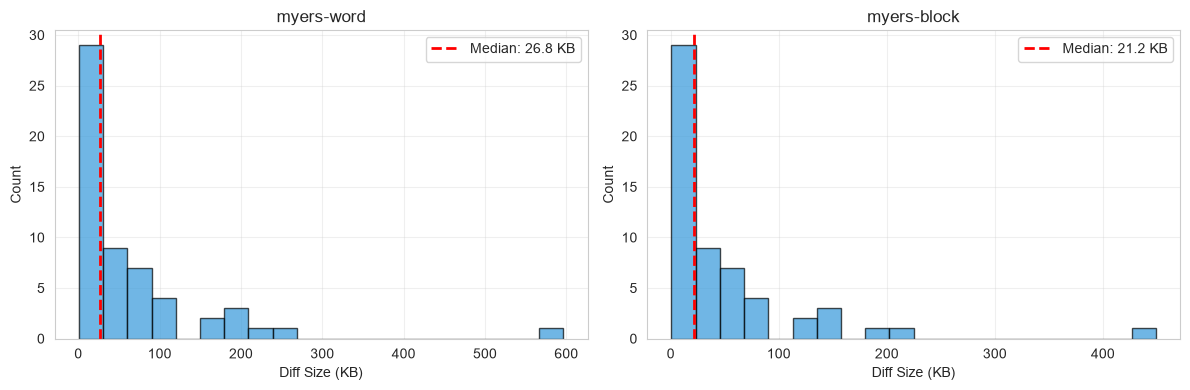

In [ ]:
if 'diff' in modes:
    print('=== STORAGE ANALYSIS (Diff Mode) ===')
    diff_data = algo_df[algo_df['mode'] == 'diff']
    
    for algo in algos:
        a = diff_data[diff_data['algo'] == algo]
        if len(a) == 0: continue
        
        total_kb = a['sizeBytes'].sum()/1024
        median_kb = a['sizeBytes'].median()/1024
        max_kb = a['sizeBytes'].max()/1024
        print(f"{algo}: {total_kb:.1f} KB total, {median_kb:.1f} KB median, {max_kb:.1f} KB max")
    
    # Histogram
    diff_algos = [a for a in algos if len(diff_data[diff_data['algo'] == a]) > 0]
    if len(diff_algos) > 0:
        fig, axes = plt.subplots(1, len(diff_algos), figsize=(6*len(diff_algos), 4))
        if len(diff_algos) == 1: 
            axes = [axes]
        
        for idx, algo in enumerate(diff_algos):
            a = diff_data[diff_data['algo'] == algo]
            axes[idx].hist(a['sizeBytes']/1024, bins=20, color='#3498db', alpha=0.7, edgecolor='black')
            axes[idx].set_xlabel('Diff Size (KB)')
            axes[idx].set_ylabel('Count')
            axes[idx].set_title(f'{algo}')
            median_kb = a['sizeBytes'].median()/1024
            axes[idx].axvline(median_kb, color='red', linestyle='--', linewidth=2,
                             label=f'Median: {median_kb:.1f} KB')
            axes[idx].legend()
            axes[idx].grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
else:
    print('NOTE: Storage analysis only applies to diff mode')

=== WIKIPEDIA CASE STUDY (diff mode) ===
Analyzing 49 links

Network phases (per link):
  Live fetch:         144.6ms avg  (σ=330.1)
  Snapshot download: 1093.9ms avg  (σ=814.9)
  Algorithm total:   5283.5ms avg  (σ=33659.4)

Algorithm phases (per algorithm run in diff mode):
  myers-word:
    Parse:    124.7ms avg  (σ=157.6)
    Compare: 2563.9ms avg  (σ=17535.2)
  myers-block:
    Parse:    160.8ms avg  (σ=259.6)
    Compare:    5.8ms avg  (σ=35.0)


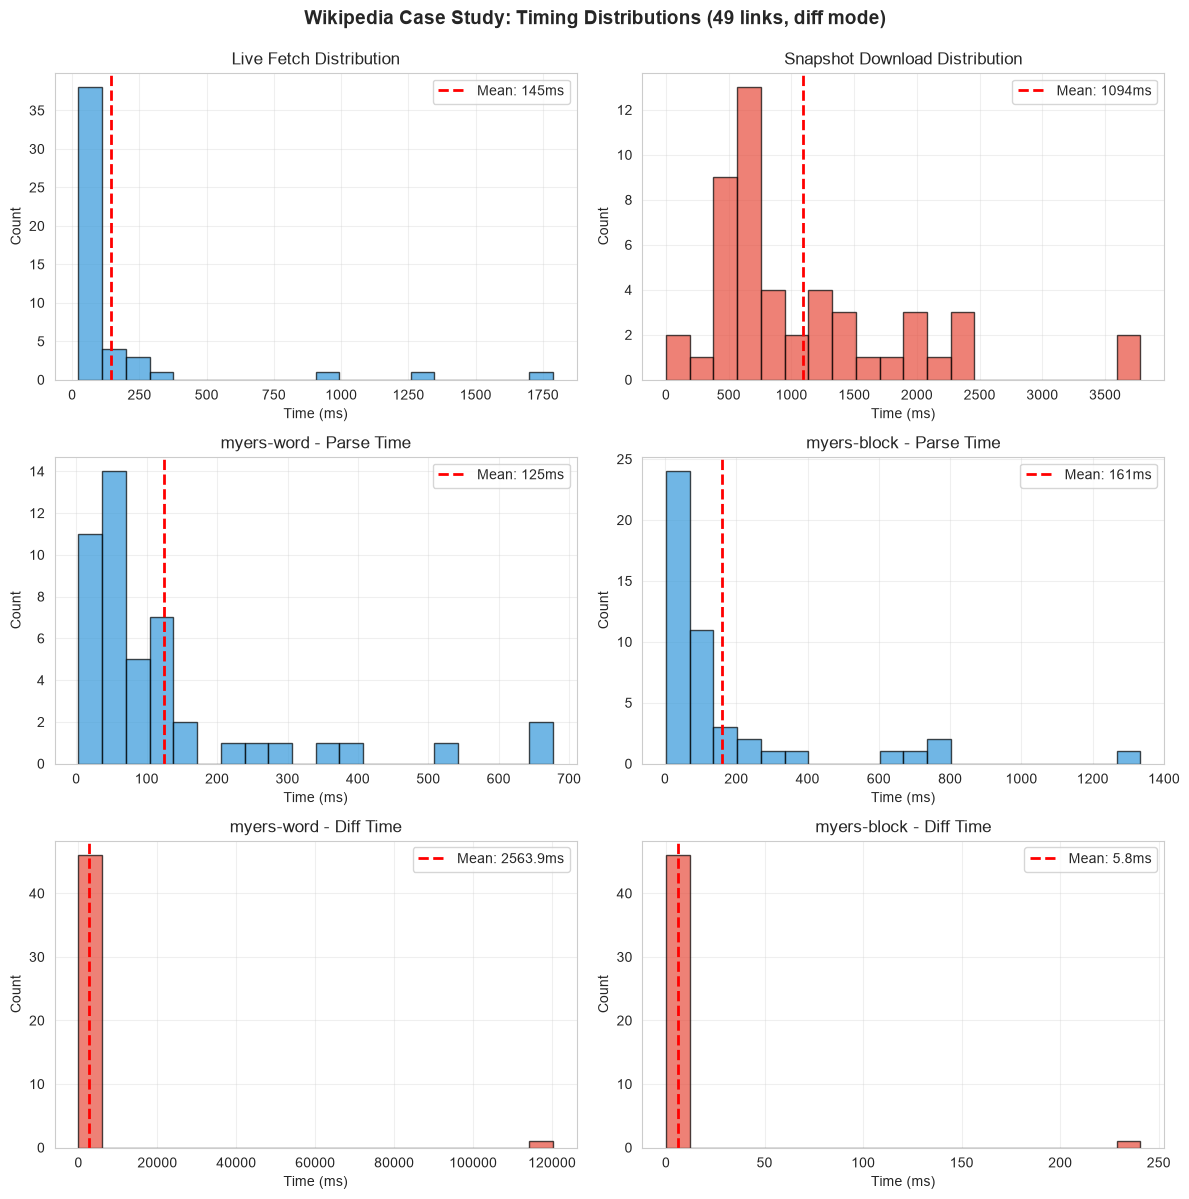


Insights:
  Snapshot download has highest variance (CV=0.74)
    - Network latency to Wayback is unpredictable
  myers-word parse time variance (CV=1.26)
    - Larger pages take longer to parse
  myers-block parse time variance (CV=1.61)
    - Larger pages take longer to parse


In [ ]:
# Configure which mode to analyze for Wikipedia case study
WIKI_MODE = 'diff' if 'diff' in modes else modes[0]

wiki_algo = algo_df[(algo_df['test'] == 'wikipedia-main') & (algo_df['mode'] == WIKI_MODE)]
wiki_net = net_df[net_df['test'] == 'wikipedia-main']

if len(wiki_algo) == 0:
    print('WARNING: No Wikipedia data found')
else:
    print(f'=== WIKIPEDIA CASE STUDY ({WIKI_MODE} mode) ===')
    print(f'Analyzing {len(wiki_net)} links')
    print(f'\nNetwork phases (per link):')
    print(f"  Live fetch:        {wiki_net['liveMs'].mean():6.1f}ms avg  (σ={wiki_net['liveMs'].std():.1f})")
    print(f"  Snapshot download: {wiki_net['snapMs'].mean():6.1f}ms avg  (σ={wiki_net['snapMs'].std():.1f})")
    print(f"  Algorithm total:   {wiki_net['algoMs'].mean():6.1f}ms avg  (σ={wiki_net['algoMs'].std():.1f})")
    
    wiki_algos = wiki_algo['algo'].unique()
    print(f'\nAlgorithm phases (per algorithm run in {WIKI_MODE} mode):')
    for algo in wiki_algos:
        w = wiki_algo[wiki_algo['algo'] == algo]
        if len(w) == 0: continue
        print(f'  {algo}:')
        print(f"    Parse:   {w['parseMs'].mean():6.1f}ms avg  (σ={w['parseMs'].std():.1f})")
        print(f"    Compare: {w['compareMs'].mean():6.1f}ms avg  (σ={w['compareMs'].std():.1f})")
    
    # Create comprehensive histogram grid
    n_algos = len(wiki_algos)
    fig, axes = plt.subplots(3, max(2, n_algos), figsize=(6*max(2, n_algos), 12))
    
    # Row 1: Network phases (shared across algorithms)
    axes[0, 0].hist(wiki_net['liveMs'], bins=20, color='#3498db', alpha=0.7, edgecolor='black')
    axes[0, 0].axvline(wiki_net['liveMs'].mean(), color='red', linestyle='--', linewidth=2,
                      label=f"Mean: {wiki_net['liveMs'].mean():.0f}ms")
    axes[0, 0].set_xlabel('Time (ms)')
    axes[0, 0].set_ylabel('Count')
    axes[0, 0].set_title('Live Fetch Distribution')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)
    
    axes[0, 1].hist(wiki_net['snapMs'], bins=20, color='#e74c3c', alpha=0.7, edgecolor='black')
    axes[0, 1].axvline(wiki_net['snapMs'].mean(), color='red', linestyle='--', linewidth=2,
                      label=f"Mean: {wiki_net['snapMs'].mean():.0f}ms")
    axes[0, 1].set_xlabel('Time (ms)')
    axes[0, 1].set_ylabel('Count')
    axes[0, 1].set_title('Snapshot Download Distribution')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)
    
    for i in range(2, max(2, n_algos)):
        axes[0, i].axis('off')
    
    # Row 2: Parse time per algorithm
    for idx, algo in enumerate(wiki_algos):
        w = wiki_algo[wiki_algo['algo'] == algo]
        if len(w) == 0: continue
        axes[1, idx].hist(w['parseMs'], bins=20, color='#3498db', alpha=0.7, edgecolor='black')
        axes[1, idx].axvline(w['parseMs'].mean(), color='red', linestyle='--', linewidth=2,
                           label=f"Mean: {w['parseMs'].mean():.0f}ms")
        axes[1, idx].set_xlabel('Time (ms)')
        axes[1, idx].set_ylabel('Count')
        axes[1, idx].set_title(f'{algo} - Parse Time')
        axes[1, idx].legend()
        axes[1, idx].grid(alpha=0.3)
    
    for i in range(len(wiki_algos), max(2, n_algos)):
        axes[1, i].axis('off')
    
    # Row 3: Compare time per algorithm
    for idx, algo in enumerate(wiki_algos):
        w = wiki_algo[wiki_algo['algo'] == algo]
        if len(w) == 0: continue
        axes[2, idx].hist(w['compareMs'], bins=20, color='#e74c3c', alpha=0.7, edgecolor='black')
        axes[2, idx].axvline(w['compareMs'].mean(), color='red', linestyle='--', linewidth=2,
                           label=f"Mean: {w['compareMs'].mean():.1f}ms")
        axes[2, idx].set_xlabel('Time (ms)')
        axes[2, idx].set_ylabel('Count')
        axes[2, idx].set_title(f'{algo} - {WIKI_MODE.title()} Time')
        axes[2, idx].legend()
        axes[2, idx].grid(alpha=0.3)
    
    for i in range(len(wiki_algos), max(2, n_algos)):
        axes[2, i].axis('off')
    
    plt.suptitle(f'Wikipedia Case Study: Timing Distributions ({len(wiki_net)} links, {WIKI_MODE} mode)',
                fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()
    
    # Insights
    print('\nInsights:')
    snap_var_coef = wiki_net['snapMs'].std() / wiki_net['snapMs'].mean()
    print(f"  Snapshot download has highest variance (CV={snap_var_coef:.2f})")
    print(f"    - Network latency to Wayback is unpredictable")
    
    for algo in wiki_algos:
        w = wiki_algo[wiki_algo['algo'] == algo]
        if len(w) == 0: continue
        parse_var_coef = w['parseMs'].std() / w['parseMs'].mean()
        print(f"  {algo} parse time variance (CV={parse_var_coef:.2f})")
        print(f"    - Larger pages take longer to parse")

Storage Analysis

=== STORAGE ANALYSIS (Diff Mode) ===
myers-word: 3534.5 KB total, 62.0 KB avg, 596.3 KB max
myers-block: 2814.0 KB total, 49.4 KB avg, 448.9 KB max


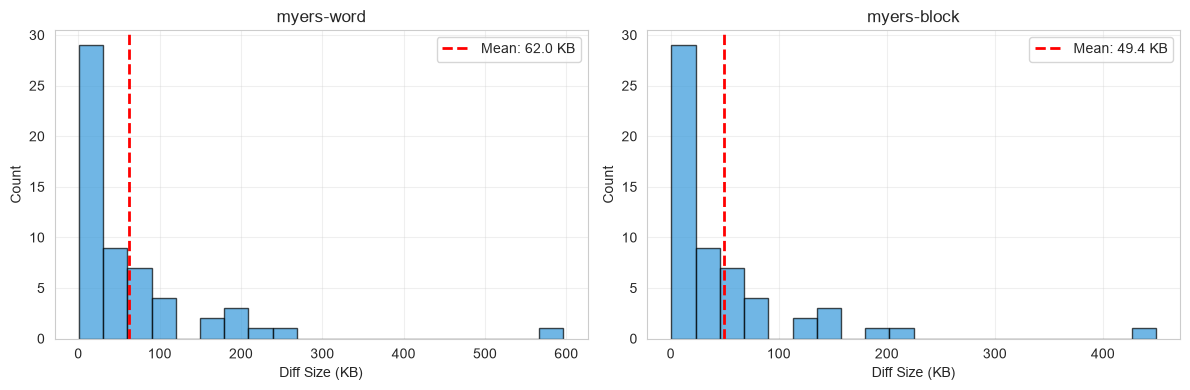

In [ ]:
if 'diff' in modes:
    print('=== STORAGE ANALYSIS (Diff Mode) ===')
    diff_data = algo_df[algo_df['mode'] == 'diff']
    
    for algo in algos:
        a = diff_data[diff_data['algo'] == algo]
        if len(a) == 0: continue
        
        total_kb = a['sizeBytes'].sum()/1024
        avg_kb = a['sizeBytes'].mean()/1024
        max_kb = a['sizeBytes'].max()/1024
        print(f"{algo}: {total_kb:.1f} KB total, {avg_kb:.1f} KB avg, {max_kb:.1f} KB max")
    
    # Histogram
    diff_algos = [a for a in algos if len(diff_data[diff_data['algo'] == a]) > 0]
    if len(diff_algos) > 0:
        fig, axes = plt.subplots(1, len(diff_algos), figsize=(6*len(diff_algos), 4))
        if len(diff_algos) == 1: 
            axes = [axes]
        
        for idx, algo in enumerate(diff_algos):
            a = diff_data[diff_data['algo'] == algo]
            axes[idx].hist(a['sizeBytes']/1024, bins=20, color='#3498db', alpha=0.7, edgecolor='black')
            axes[idx].set_xlabel('Diff Size (KB)')
            axes[idx].set_ylabel('Count')
            axes[idx].set_title(f'{algo}')
            mean_kb = a['sizeBytes'].mean()/1024
            axes[idx].axvline(mean_kb, color='red', linestyle='--', linewidth=2,
                             label=f'Mean: {mean_kb:.1f} KB')
            axes[idx].legend()
            axes[idx].grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
else:
    print('NOTE: Storage analysis only applies to diff mode')